# Wetland Mapping with TropWet: Finding the Endmembers in the Image

*Section 13 — Case study: wetland mapping (TropWet), notebook 4 of 6.* Previous: `03_change_and_accuracy`. Next: `05_mesma_and_comparison`.

TropWet chooses its endmembers with fixed NDVI and MNDWI rules (Hardy et al., 2020). Notebook 01 showed what that gives in the Rufiji delta: plenty of water and vegetation pixels, but only a couple of hundred "sand" pixels, which are wet mud. This notebook lets the image speak instead, with the standard endmember methods of rsgispy 0.5.1 (`rsgispy.imagespectral.endmember_extract`):

1. **How many endmembers are there?** HySime (Bioucas-Dias & Nascimento, 2008) and the virtual dimensionality by the Harsanyi–Farrand–Chang method (HFC; Chang & Du, 2004).
2. **Which pixels are the endmembers?** Three geometric methods that look for the corners of the data cloud: ATGP (Ren & Chang, 2003), VCA (Nascimento & Bioucas-Dias, 2005) and N-FINDR (Winter, 1999), and the Pixel Purity Index (Boardman et al., 1995) on MNF components.
3. **What difference does it make?** Each endmember set is used in the published TropWet workflow (FCLS and the TropWet class rules) and compared with the published method: the unmixing error, the class areas, the per-pixel agreement and the reference polygons of notebook 03.

**You will learn:**
- how to estimate the number of endmembers with `estimate_n_endmembers_hysime` and `estimate_n_endmembers_hfc`;
- how to extract endmembers with `extract_endmembers_atgp`, `extract_endmembers_vca` and `extract_endmembers_nfindr`, and where the selected pixels are;
- how to run the PPI workflow: `calc_mnf`, `calc_ppi` and `select_ppi_endmembers`;
- why the endmembers that fit the image best are not necessarily the best endmembers for a rule-based classification.

**Before you start:** run notebooks 01–03; this notebook reads the composite, the TropWet endmembers, the published classification (notebook 02) and the reference rasters (notebook 03).

**Data:** `outputs/inputs/`, `outputs/endmembers/`, `outputs/unmixing/` and `outputs/change/`. Outputs are written to `outputs/extraction/`.

**Run time:** ~1.5 minutes.

## Running Notebook

The notebook has been run and saved with the outputs so you can see what the outputs should be and so the notebook can be browsed online without having to run the notebook for it to make sense.

If you are running the notebook for yourself it is recommended that you clear the existing outputs which can be done by running one of the following options depending on what system you are using:

**Jupyter-lab**:

> \> _Edit_ \> _'Clear All Outputs'_

**Jupyter-notebook**:

> \> _Cell_ \> _'All Outputs'_ \> _Clear_

## 1. Import Modules

In [1]:
# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

import rsgispy
import rsgispy.imagespectral.endmember_extract as em_ext
import rsgispy.imagespectral.endmembers as spec_em
import rsgispy.imagespectral.unmixing as unmix
from rsgispy.imagecalc.maths import BandDefn, band_maths
from rsgispy.imagecalc.stats import count_pxls_of_val
from rsgispy.imagespectral.transforms import calc_mnf
from rsgispy.imageutils.colourtable import set_thematic_classes
from rsgispy.mapping.layout import MapPanel, create_map_panels
from rsgispy.tools.plotting import plot_2d_img_histogram

## 2. Define Input Data and Directories

In [2]:
in_dir = os.path.join("outputs", "inputs")
em_dir = os.path.join("outputs", "endmembers")
unmix_dir = os.path.join("outputs", "unmixing")
chg_dir = os.path.join("outputs", "change")
ext_dir = os.path.join("outputs", "extraction")
os.makedirs(ext_dir, exist_ok=True)

refl_scale = 1000.0  # the images are reflectance x 1000
comp_img = os.path.join(in_dir, "sref_composite.tif")
idx_img = os.path.join(in_dir, "composite_indices.tif")  # NDVI, MNDWI
wavelengths = [482, 561, 655, 865, 1609, 2201]
em_tropwet_df = spec_em.read_endmembers_df(os.path.join(em_dir, "endmembers_tropwet.csv"))
em_tropwet_df.round(0)

,Water,Vegetation,Sand
band,,,
Blue,58.0,25.0,63.0
Green,80.0,47.0,97.0
Red,64.0,34.0,104.0
NIR,32.0,317.0,146.0
SWIR1,12.0,123.0,103.0
SWIR2,11.0,55.0,66.0


## 3. How Many Endmembers?

Both methods work on a sample of the valid pixels (up to 200,000, chosen with a seeded key per pixel, so the sample does not depend on how the image is read).

- **HySime** estimates the noise of each band by regressing it on the other bands, then keeps the signal components whose power is larger than twice their noise power (the subspace that minimises the mean squared error).
- **HFC** compares the eigenvalues of the correlation and covariance matrices: a component carries signal when the difference is larger than a Neyman–Pearson threshold for the false-alarm probability (here 10⁻³).

HySime: 3 endmembers; HFC: 5 endmembers


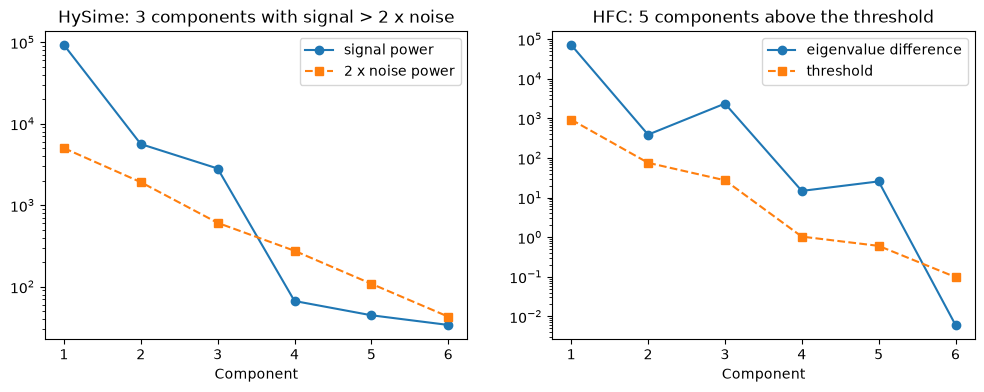

In [3]:
n_hysime, hysime_diag = em_ext.estimate_n_endmembers_hysime(comp_img, rnd_seed=42, use_pbar=False)
n_hfc, hfc_diag = em_ext.estimate_n_endmembers_hfc(comp_img, false_alarm=1e-3, rnd_seed=42,
                                                  use_pbar=False)
print(f"HySime: {n_hysime} endmembers; HFC: {n_hfc} endmembers")

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].semilogy(hysime_diag["component"], hysime_diag["signal_power"], "o-", label="signal power")
axs[0].semilogy(hysime_diag["component"], 2 * hysime_diag["noise_power"], "s--",
                label="2 x noise power")
axs[0].set_title(f"HySime: {n_hysime} components with signal > 2 x noise")
axs[1].semilogy(hfc_diag["component"], hfc_diag["eig_corr"] - hfc_diag["eig_cov"], "o-",
                label="eigenvalue difference")
axs[1].semilogy(hfc_diag["component"], hfc_diag["threshold"], "s--", label="threshold")
axs[1].set_title(f"HFC: {n_hfc} components above the threshold")
for ax in axs:
    ax.set_xlabel("Component")
    ax.legend()
plt.show()

The two estimates differ. **HySime finds three** components with more signal than noise, which matches the three TropWet endmembers. **HFC finds five**: with 200,000 pixels even the small eigenvalue differences of components 4 and 5 are statistically significant, although their signal is tiny (the eigenvalue differences drop by two orders of magnitude after component 3). With only six Landsat bands, at most five endmembers can be distinguished from the mean, so HFC is close to its limit. The rest of the notebook uses three endmembers, as TropWet does; three is also all a six-band image can unmix robustly.

## 4. Extracting Three Endmembers from the Image

ATGP, VCA and N-FINDR all assume that the purest pixels sit at the corners of the data cloud:

- **ATGP** starts from the brightest pixel and repeatedly takes the pixel furthest from the space spanned by the endmembers found so far.
- **VCA** projects the data onto random directions orthogonal to the endmembers found so far and takes the most extreme pixel.
- **N-FINDR** looks for the pixels spanning the simplex (here a triangle) of largest volume, starting from the ATGP pixels.

All three return image pixels; `return_coords=True` also gives their row, column and map coordinates. Three endmembers are asked for, as in TropWet.

In [4]:
extractors = {
    "ATGP": em_ext.extract_endmembers_atgp,
    "VCA": em_ext.extract_endmembers_vca,
    "N-FINDR": em_ext.extract_endmembers_nfindr,
}
ext_dfs, ext_coords = {}, {}
for name, extract_fn in extractors.items():
    ext_dfs[name], ext_coords[name] = extract_fn(
        comp_img, 3, return_coords=True, rnd_seed=42, use_pbar=False
    )
pd.concat(ext_coords, names=["method"]).round(0)

endmember  row  col         x         y
method                                              
ATGP    0  endmember_1  624  473  537215.0 -872734.0
        1  endmember_2  727  288  531665.0 -875824.0
        2  endmember_3  166   27  523835.0 -858994.0
VCA     0  endmember_1   91  787  546635.0 -856744.0
        1  endmember_2  600  699  543995.0 -872014.0
        2  endmember_3   88  361  533855.0 -856654.0
N-FINDR 0  endmember_1  624  473  537215.0 -872734.0
        1  endmember_2  727  288  531665.0 -875824.0
        2  endmember_3  114  717  544535.0 -857434.0

### 4.1 Naming the endmembers

The methods do not know which endmember is which. `name_endmembers` assigns the names by the indices of each spectrum: the highest MNDWI is water, the highest NDVI of the rest is vegetation and the last one is "sand". `spectral_angle` measures how similar two spectra are, independent of their brightness (0° = the same shape).

In [5]:
def name_endmembers(em_df):
    """
    Order and name three endmembers as Water, Vegetation and Sand; return the
    renamed table and the mapping from the original names.
    """
    ndvi = (em_df.loc["NIR"] - em_df.loc["Red"]) / (em_df.loc["NIR"] + em_df.loc["Red"])
    mndwi = (em_df.loc["Green"] - em_df.loc["SWIR1"]) / (em_df.loc["Green"] + em_df.loc["SWIR1"])
    water = mndwi.idxmax()
    veg = ndvi.drop(water).idxmax()
    sand = [col for col in em_df.columns if col not in (water, veg)][0]
    mapping = {water: "Water", veg: "Vegetation", sand: "Sand"}
    return em_df[[water, veg, sand]].rename(columns=mapping), mapping


def spectral_angle(spec_a, spec_b):
    """Spectral angle (degrees) between two spectra."""
    cos = np.dot(spec_a, spec_b) / (np.linalg.norm(spec_a) * np.linalg.norm(spec_b))
    return np.degrees(np.arccos(np.clip(cos, -1.0, 1.0)))


for name in ext_dfs:
    ext_dfs[name], mapping = name_endmembers(ext_dfs[name])
    ext_coords[name]["name"] = ext_coords[name]["endmember"].map(mapping)

pd.DataFrame(
    {
        name: {em: spectral_angle(em_df[em], em_tropwet_df[em]) for em in em_df.columns}
        for name, em_df in ext_dfs.items()
    }
).round(1).rename_axis("angle to TropWet (deg)")

,ATGP,VCA,N-FINDR
angle to TropWet (deg),,,
Water,42.9,10.6,10.6
Vegetation,4.7,14.7,4.7
Sand,26.4,29.5,14.7


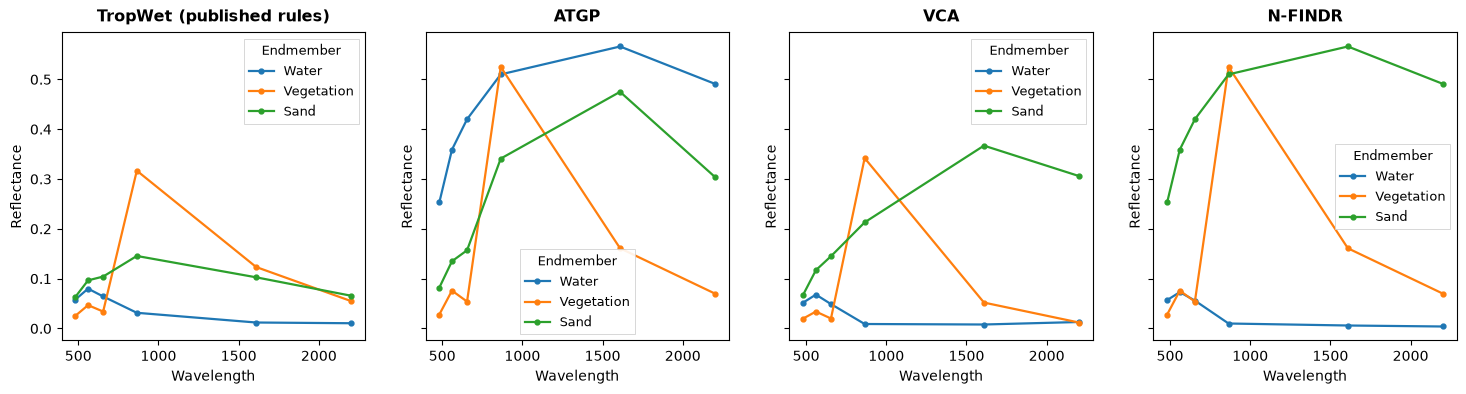

In [6]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
spec_em.plot_endmembers(em_tropwet_df, gain=refl_scale, wavelengths=wavelengths,
                        plot_title="TropWet (published rules)", ax=axs[0])
for ax, (name, em_df) in zip(axs[1:], ext_dfs.items()):
    spec_em.plot_endmembers(em_df, gain=refl_scale, wavelengths=wavelengths,
                            plot_title=name, ax=ax)
plt.show()

All three methods find a **vegetation** endmember that is close to the TropWet one (5° for ATGP and N-FINDR): dense green vegetation is a clear corner of the data cloud. The other two endmembers are different:

- **Water.** VCA and N-FINDR pick a pixel of clear, dark sea water (10.6° from the TropWet water, which is the mean of the turbid water of the channels and the river mouth). ATGP does not find water at all: it starts from the *brightest* pixel and takes the pixel furthest from the endmembers already found, so the dark water corner, close to the origin, is never selected among the first three. Its "water" is a bright bare surface.
- **Sand.** All the "sand" endmembers are much brighter than the TropWet wet mud (reflectance up to 0.4–0.6 in the SWIR): the brightest bare surfaces of the scene.

### 4.2 Where are the selected pixels?

The NDVI / MNDWI feature space of notebook 01 shows where the selected pixels sit relative to the TropWet rules, and a map shows where they are.

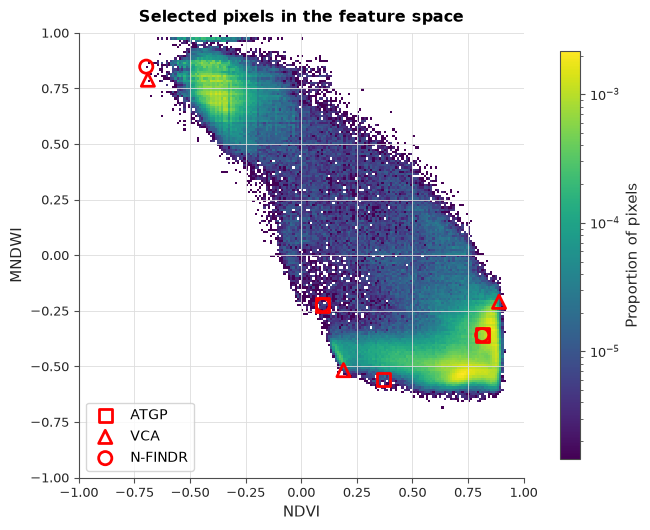

In [7]:
markers = {"ATGP": "s", "VCA": "^", "N-FINDR": "o"}
with rasterio.open(idx_img) as src:
    idx_arr = src.read()

fig, ax = plot_2d_img_histogram(
    idx_img, x_band=1, y_band=2, bins=200, x_range=(-1, 1), y_range=(-1, 1),
    x_label="NDVI", y_label="MNDWI", title="Selected pixels in the feature space",
    use_pbar=False,
)
for name, coords in ext_coords.items():
    rows, cols = coords["row"].to_numpy(), coords["col"].to_numpy()
    ax.scatter(idx_arr[0, rows, cols], idx_arr[1, rows, cols], marker=markers[name], s=90,
               facecolor="none", edgecolor="red", linewidth=2, label=name)
ax.legend(loc="lower left")
plt.show()

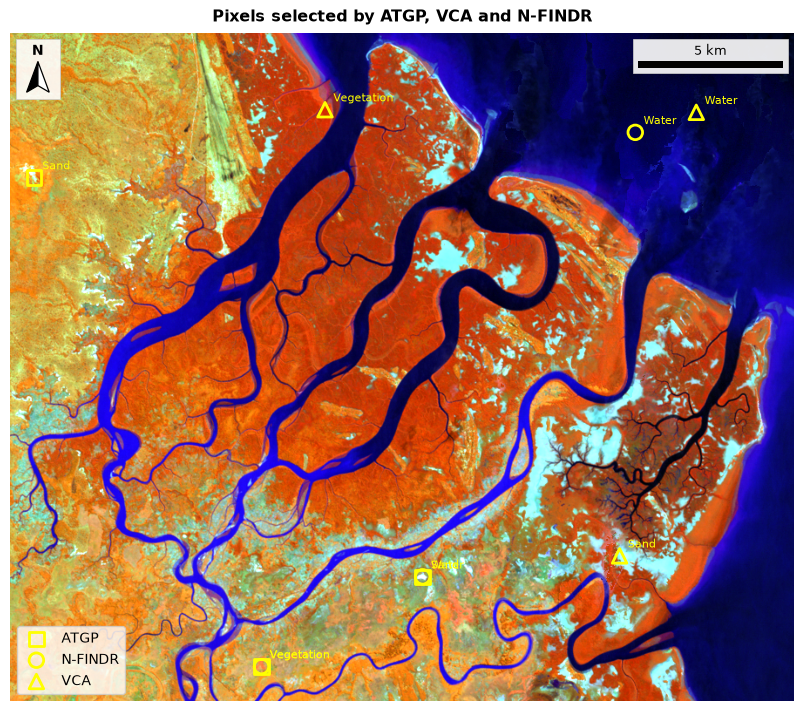

In [8]:
pts = pd.concat(ext_coords, names=["method"]).reset_index(level=0)
fig, axs = create_map_panels(
    [MapPanel("rgb", comp_img, bands=[4, 5, 3], title="Pixels selected by ATGP, VCA and N-FINDR")],
    figsize=(8, 7),
)
for name, grp in pts.groupby("method"):
    axs[0].scatter(grp["x"], grp["y"], marker=markers[name], s=110, facecolor="none",
                   edgecolor="yellow", linewidth=2, label=name)
    for _, rec in grp.iterrows():
        axs[0].annotate(rec["name"], (rec["x"], rec["y"]), xytext=(6, 6),
                        textcoords="offset points", color="yellow", fontsize=8)
axs[0].legend(loc="lower left")
plt.show()

The selected water pixels are open sea, far from the channels; the bright "sand" pixels are bare fields and salt flats in the south and west, and at one bright spot on the coast. Each is a **single pixel**, chosen because it is extreme, so noise, a bright roof or a sun glint can decide it. In the feature space they sit at the very corners of the cloud, outside the TropWet rules for water and sand.

## 5. The Pixel Purity Index on MNF Components

The PPI workflow first reduces the image to its signal components with the Minimum Noise Fraction (MNF), counts how often each pixel is the most extreme along random directions ("skewers") with `calc_ppi`, and then clusters the purest pixels into endmember spectra with `select_ppi_endmembers` (k-means on the reflectance spectra of the pixels with a count of at least `min_ppi`). The first three MNF components are kept, as HySime found three endmembers.

In [9]:
mnf_img = os.path.join(ext_dir, "composite_mnf.tif")
mnf_info = calc_mnf(comp_img, mnf_img, n_components=3, calc_stats=False, use_pbar=False)
print("MNF signal-to-noise ratios:", np.round(mnf_info["snr_estimates"], 1))

ppi_img = os.path.join(ext_dir, "composite_ppi.tif")
spec_em.calc_ppi(mnf_img, ppi_img, n_skewers=5000, rnd_seed=42, calc_stats=False,
                 use_pbar=False)
with rasterio.open(ppi_img) as src:
    ppi_arr = src.read(1)
print(f"{np.sum(ppi_arr > 0)} pixels were extreme at least once; the largest count is "
      f"{ppi_arr.max()}")

ppi_pts_file = os.path.join(ext_dir, "ppi_endmember_pixels.gpkg")
ext_dfs["PPI"], _ = name_endmembers(
    em_ext.select_ppi_endmembers(
        comp_img, ppi_img, 3, min_ppi=5, out_vec_file=ppi_pts_file, out_vec_lyr="ppi",
        rnd_seed=42, use_pbar=False,
    )
)
ext_dfs["PPI"].round(0)

MNF signal-to-noise ratios: [73.4 16.8 14.6]


66 pixels were extreme at least once; the largest count is 1520


,Water,Vegetation,Sand
band,,,
Blue,63.0,25.0,128.0
Green,83.0,48.0,192.0
Red,70.0,36.0,227.0
NIR,52.0,386.0,369.0
SWIR1,8.0,129.0,494.0
SWIR2,10.0,72.0,381.0


In [10]:
pd.DataFrame(
    {
        name: {em: spectral_angle(em_df[em], em_tropwet_df[em]) for em in em_df.columns}
        for name, em_df in ext_dfs.items()
    }
).round(1).rename_axis("angle to TropWet (deg)")

,ATGP,VCA,N-FINDR,PPI
angle to TropWet (deg),,,,
Water,42.9,10.6,10.6,8.0
Vegetation,4.7,14.7,4.7,3.2
Sand,26.4,29.5,14.7,22.7


With 5,000 skewers, only 66 pixels are ever the most extreme, and the clusters of those with a count of at least 5 give spectra that are averages of several extreme pixels: water and vegetation close to the TropWet ones (8° and 3°), and a "sand" that is again a bright surface (23°). PPI is the method closest to the published endmembers here, but it is also the slowest (about 30 s for the PPI) and depends on `min_ppi`, the number of skewers and the MNF components kept.

## 6. Unmixing and Classifying with Each Endmember Set

Each set is now used exactly as in the published method: FCLS, the fractions as percentages and the TropWet class rules (the helper functions of notebook 02).

In [11]:
TROPWET_CLASSES = {
    1: ("Open Water (OW)", "#08519C"),
    2: ("Emergent Flooded Vegetation (EFV)", "#3FB8AF"),
    3: ("Wet Bare Sand (WBS)", "#B39C4D"),
    4: ("Dense Vegetation (GV)", "#1B7837"),
    5: ("Dry Sparse Vegetation (DSV)", "#A6D96A"),
    6: ("Dry Bare Sand (DBS)", "#F4E2B8"),
    7: ("Mixed / Other", "#BDBDBD"),
}
cls_names = {val: name for val, (name, _) in TROPWET_CLASSES.items()}
cls_abbrv = {val: name.split("(")[-1].rstrip(")") if "(" in name else "Other"
             for val, name in cls_names.items()}


def fracs_to_pct(frac_img, pct_img):
    """FCLS fractions (no data -9999) to percentages (no data -999)."""
    band_maths(
        pct_img,
        ", ".join(f"{name} == -9999 ? -999 : 100 * {name}" for name in "WVS"),
        [BandDefn(name, frac_img, idx) for idx, name in enumerate("WVS", start=1)],
        band_names=["Water", "Vegetation", "Sand"],
        no_data_val=-999,
        use_pbar=False,
    )
    return pct_img


def classify_tropwet(pct_img, cls_img, hi=75, lo=25):
    """TropWet class rules (Hardy et al., 2020, Table 3) on W, V, S in %."""
    rules = [
        (1, f"W >= {hi}"),
        (2, f"W + V >= {hi} && V >= {lo} && V < {hi} && W >= {lo} && W < {hi}"),
        (3, f"W + S >= {hi} && W >= {lo} && W < {hi} && S >= {lo} && S < {hi}"),
        (4, f"V >= {hi}"),
        (5, f"V + S >= {hi} && V >= {lo} && V < {hi} && S >= {lo} && S < {hi}"),
        (6, f"S >= {hi}"),
    ]
    exp = "W < 0 ? 0 : "  # no data
    for code, rule in rules:
        exp += f"(({rule}) ? {code} : "
    exp += "7" + ")" * len(rules)  # anything else: Mixed / Other
    band_maths(
        cls_img,
        exp,
        [BandDefn(name, pct_img, idx) for idx, name in enumerate("WVS", start=1)],
        datatype=rsgispy.TYPE_8UINT,
        band_names=["tropwet_class"],
        no_data_val=0,
        use_pbar=False,
    )
    set_thematic_classes(cls_img, TROPWET_CLASSES)
    return cls_img


def class_areas_ha(cls_img):
    """Area (ha) of each TropWet class."""
    with rasterio.open(cls_img) as src:
        pxl_ha = abs(src.res[0] * src.res[1]) / 10000.0
    counts = count_pxls_of_val(cls_img, list(TROPWET_CLASSES), img_band=1, use_pbar=False)
    return pd.Series(counts * pxl_ha, index=pd.Index(cls_abbrv.values(), name="class"))

In [12]:
all_sets = {"TropWet": em_tropwet_df, **ext_dfs}
frac_imgs, err_imgs, cls_imgs = {}, {}, {}
for name, em_df in all_sets.items():
    tag = name.lower().replace("-", "")
    frac_imgs[name] = os.path.join(ext_dir, f"composite_{tag}_fcls.tif")
    err_imgs[name] = os.path.join(ext_dir, f"composite_{tag}_fcls_err.tif")
    unmix.spec_unmix_fcls(comp_img, frac_imgs[name], em_df, use_pbar=False)
    unmix.calc_unmixing_rmse_residual_err(comp_img, frac_imgs[name], err_imgs[name], em_df,
                                          use_pbar=False)
    pct_img = fracs_to_pct(frac_imgs[name], os.path.join(ext_dir, f"composite_{tag}_pct.tif"))
    cls_imgs[name] = classify_tropwet(pct_img, os.path.join(ext_dir, f"composite_{tag}_classes.tif"))

## 7. Comparison with the Published Method

### 7.1 Error, class areas and agreement

The published method is the TropWet set of notebook 02 (the same result, recomputed here). For every set: the median and 99th percentile RMSE (reflectance x 1000), the area of each class and the share of pixels with the same class as the published method.

In [13]:
def read_band(img, band=1):
    with rasterio.open(img) as src:
        return src.read(band)


# The published method (notebook 02): TropWet endmembers, FCLS, TropWet rules.
published_cls_img = os.path.join(unmix_dir, "composite_tropwet_classes.tif")
published_cls = read_band(published_cls_img)


def agreement_with_published(cls_img):
    """Share (%) of the pixels with the same class as the published method."""
    cls_arr = read_band(cls_img)
    vld = (cls_arr > 0) & (published_cls > 0)
    return 100 * np.mean(cls_arr[vld] == published_cls[vld])


def from_to_published(cls_img):
    """Area (ha) of each published class (rows) in each class of cls_img (columns)."""
    cls_arr = read_band(cls_img)
    vld = (cls_arr > 0) & (published_cls > 0)
    order = list(cls_abbrv.values())
    tab = pd.crosstab(
        pd.Series(published_cls[vld], name="published").map(cls_abbrv),
        pd.Series(cls_arr[vld], name="this set").map(cls_abbrv),
    ) * 0.09
    return tab.reindex(index=order, columns=order, fill_value=0)


# Reference polygons of notebook 03 (water, mangroves, other terrestrial),
# rasterised on the 1997 and 2018 images; both are on the composite's grid.
ref_97 = read_band(os.path.join(chg_dir, "reference_1997.tif"))
ref_18 = read_band(os.path.join(chg_dir, "reference_2018.tif"))
ref_arr = np.where(ref_97 > 0, ref_97, ref_18)
ref_arr[(ref_97 > 0) & (ref_18 > 0) & (ref_97 != ref_18)] = 0  # disagreeing labels


def reference_check(cls_img):
    """% of the water reference mapped as Open Water, of the mangroves as
    vegetated (GV or EFV) and of the other land as a dry class (GV, DSV, DBS)."""
    cls_arr = read_band(cls_img)
    vld = (ref_arr > 0) & (cls_arr > 0)
    ref, cls_v = ref_arr[vld], cls_arr[vld]
    return pd.Series({
        "water -> OW (%)": 100 * np.mean(cls_v[ref == 1] == 1),
        "mangroves -> GV or EFV (%)": 100 * np.mean(np.isin(cls_v[ref == 2], [2, 4])),
        "other land -> GV, DSV or DBS (%)": 100 * np.mean(np.isin(cls_v[ref == 3], [4, 5, 6])),
    })

In [14]:
def rmse_stats(err_img):
    err = read_band(err_img)
    vld = err != -9999
    return {"RMSE median": np.median(err[vld]), "RMSE p99": np.percentile(err[vld], 99)}


cmp_df = pd.DataFrame(
    {
        name: {
            **rmse_stats(err_imgs[name]),
            **class_areas_ha(cls_imgs[name]).to_dict(),
            "agreement (%)": agreement_with_published(cls_imgs[name]),
        }
        for name in all_sets
    }
)
cmp_df.round(1)

,TropWet,ATGP,VCA,N-FINDR,PPI
RMSE median,18.2,98.3,10.7,22.2,15.7
RMSE p99,129.9,217.4,45.8,56.8,29.5
OW,15610.8,1.8,16426.9,17346.9,17281.2
EFV,2608.6,0.0,3143.1,40660.1,16218.1
WBS,1398.6,24.6,199.2,1577.1,2000.4
GV,33340.6,47371.0,17190.4,772.9,15268.6
DSV,8112.6,13945.7,19022.7,22.2,1444.7
DBS,474.6,755.5,1091.2,7.8,173.1
Other,581.2,28.5,5053.6,1740.0,9741.0
agreement (%),100.0,51.7,66.4,30.3,54.0


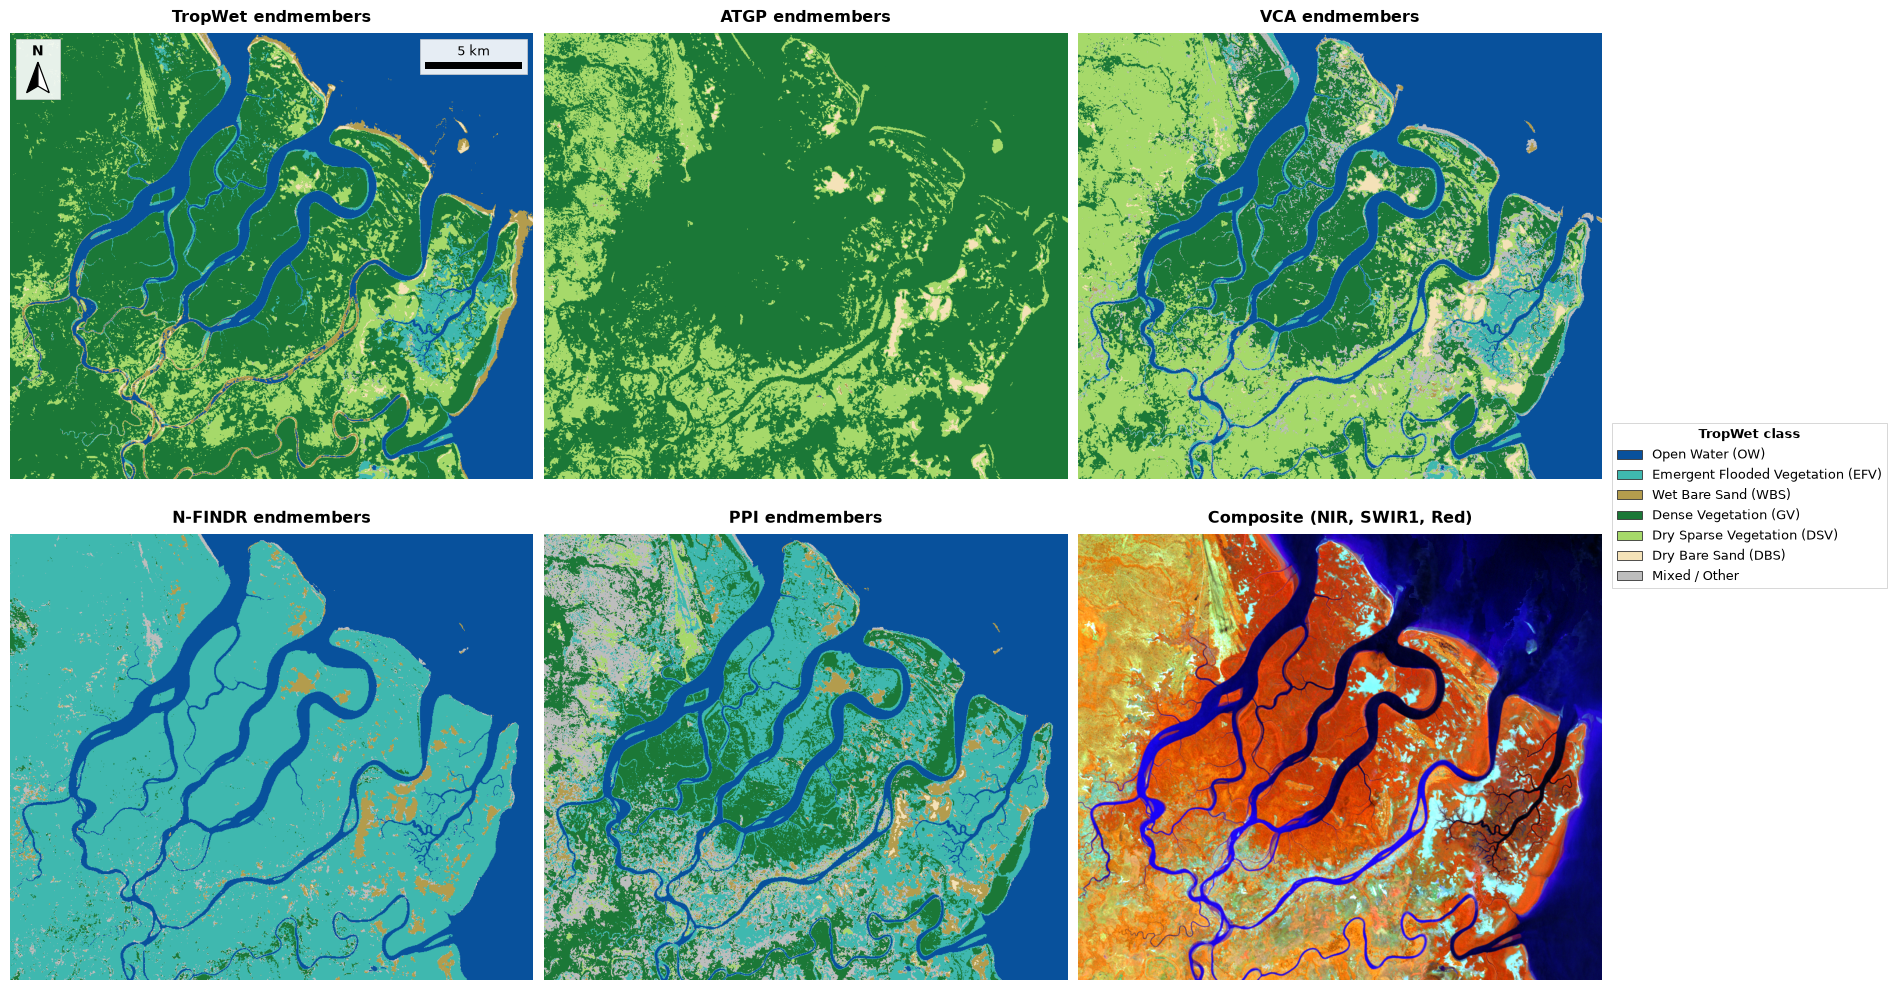

In [15]:
fig, axs = create_map_panels(
    [MapPanel("thematic", cls_imgs[name], title=f"{name} endmembers") for name in all_sets]
    + [MapPanel("rgb", comp_img, bands=[4, 5, 3], title="Composite (NIR, SWIR1, Red)")],
    ncols=3,
    figsize=(16, 10),
    legend_title="TropWet class",
)

**How different are the results from the published method? Very.** None of the image-derived sets agrees with the published classification for more than two thirds of the pixels:

- **Lower error does not mean better classes.** VCA and PPI fit the image much better than the TropWet endmembers (99th percentile RMSE 46 and 30, against 130), because their bright "sand" encloses the bright dry ground that the wet mud endmember cannot model. But their classes agree with the published map for only 66 % and 54 % of the pixels.
- **The class rules are tied to the endmembers.** The TropWet limits (75 % / 25 %) were set for endmembers that are *typical* water, vegetation and sand. With an extreme endmember, the same surface gets different fractions: with N-FINDR's very bright sand, the darker mangrove canopy needs some water to be modelled, so 40,660 ha become Emergent Flooded Vegetation (published: 2,609 ha). With the dark sea water endmember, the turbid shallows that the published method calls Wet Bare Sand are modelled as water and become Open Water.
- **ATGP fails completely** for this purpose: without a water endmember, almost nothing is Open Water.

Open water is the most robust class: VCA, N-FINDR and PPI map 16,400–17,350 ha against 15,611 ha for the published method. The mixed classes and the vegetation classes are the most sensitive to the endmembers.

### 7.2 Where do the classes go?

The from–to table of the N-FINDR set against the published method (area in ha; rows = the published class, columns = the N-FINDR class) shows which classes are swapped.

In [16]:
from_to_published(cls_imgs["N-FINDR"]).round(0)

this set,OW,EFV,WBS,GV,DSV,DBS,Other
published,,,,,,,
OW,15611.0,0.0,0.0,0.0,0.0,0.0,0.0
EFV,205.0,2388.0,0.0,0.0,0.0,0.0,16.0
WBS,1347.0,1.0,0.0,0.0,0.0,0.0,50.0
GV,0.0,31833.0,1.0,773.0,22.0,3.0,708.0
DSV,0.0,6004.0,1423.0,0.0,0.0,4.0,682.0
DBS,95.0,15.0,153.0,0.0,0.0,0.0,212.0
Other,89.0,420.0,0.0,0.0,0.0,0.0,72.0


The N-FINDR classes swap whole classes rather than nibbling at the edges: almost all of the published Dense Vegetation (31,833 of 33,341 ha) and three quarters of the Dry Sparse Vegetation become Emergent Flooded Vegetation, and the published Wet Bare Sand (turbid shallows) becomes Open Water.

### 7.3 Checking against the reference polygons

The reference polygons of notebook 03 (water, mangroves and other terrestrial land, rasterised on the 1997 and 2018 images) give an independent check. Pixels with different labels in the two years are left out.

In [17]:
pd.DataFrame({name: reference_check(cls_imgs[name]) for name in all_sets}).round(1)

,TropWet,ATGP,VCA,N-FINDR,PPI
water -> OW (%),97.4,0.0,98.0,98.5,98.5
mangroves -> GV or EFV (%),98.7,99.2,92.7,100.0,98.7
"other land -> GV, DSV or DBS (%)",99.6,99.7,95.3,4.3,38.3


The reference polygons confirm it. All sets with a water endmember map the water polygons as Open Water (97–99 %), and almost all map the mangroves as vegetated. But only the published TropWet endmembers (and ATGP, which maps nearly everything as vegetation) keep the other land in a dry class: with the N-FINDR and PPI endmembers, most of the farmland and dry ground is called a wetland (4 % and 38 % in a dry class). For a wetland map, the published endmembers are clearly better here, although their error is the highest.

## 8. Summary

- HySime estimates three endmembers, as TropWet uses; HFC estimates five, at the limit of what six bands can separate.
- ATGP, VCA, N-FINDR and PPI find the **extremes** of the data: clear sea water, very bright bare ground and the greenest vegetation. ATGP misses the dark water corner altogether.
- These endmembers fit the image better (lower RMSE) but change the classes completely: 30–66 % agreement with the published method, and the dry land becomes "wetland", because the TropWet class limits assume typical, not extreme, endmembers.
- For TropWet, image-derived endmembers are useful to **check** the published ones (is there a surface they cannot model?), not to replace them. If the endmembers are changed, the class limits have to be recalibrated with reference data.

Next, notebook `05_mesma_and_comparison` keeps the TropWet idea of endmembers from known surfaces, but uses many spectra per class (a spectral library) and lets MESMA choose the best combination for every pixel.

**References**
- Bioucas-Dias, J. M., Nascimento, J. M. P. (2008). Hyperspectral subspace identification. *IEEE Transactions on Geoscience and Remote Sensing*, 46(8), 2435–2445.
- Boardman, J. W., Kruse, F. A., Green, R. O. (1995). Mapping target signatures via partial unmixing of AVIRIS data. *Summaries of the Fifth JPL Airborne Earth Science Workshop*, JPL Publication 95-1, 23–26.
- Chang, C.-I., Du, Q. (2004). Estimation of number of spectrally distinct signal sources in hyperspectral imagery. *IEEE Transactions on Geoscience and Remote Sensing*, 42(3), 608–619.
- Hardy, A., Oakes, G., Ettritch, G. (2020). Tropical Wetland (TropWet) Mapping Tool: The Automatic Detection of Open and Vegetated Waterbodies in Google Earth Engine for Tropical Wetlands. *Remote Sensing*, 12(7), 1182. https://doi.org/10.3390/rs12071182
- Nascimento, J. M. P., Bioucas-Dias, J. M. (2005). Vertex component analysis: a fast algorithm to unmix hyperspectral data. *IEEE Transactions on Geoscience and Remote Sensing*, 43(4), 898–910.
- Ren, H., Chang, C.-I. (2003). Automatic spectral target recognition in hyperspectral imagery. *IEEE Transactions on Aerospace and Electronic Systems*, 39(4), 1232–1249.
- Winter, M. E. (1999). N-FINDR: an algorithm for fast autonomous spectral end-member determination in hyperspectral data. *Proceedings of SPIE*, 3753, 266–275.

Landsat data courtesy of the U.S. Geological Survey.